# **Machine Learning - Assignment-2**


### **Name - Yash D. Gohil**

### **BITS Id - 2026AJ05448**

In [3]:
   %pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, classification_report,
                             ConfusionMatrixDisplay)

In [5]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore")

# The saved models go into this folder (it is part of the GitHub repository)
os.makedirs("model", exist_ok=True)

def compute_metrics(model, X_eval, y_eval):
    # The six metrics required in the assignment. The target has 3 classes, so
    # AUC is one-vs-rest and Precision / Recall / F1 are macro-averaged.
    # The same function is reused later to check the saved models (what Streamlit will do).
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        "Accuracy":  accuracy_score(y_eval, y_pred),
        "AUC":       roc_auc_score(y_eval, y_proba, multi_class="ovr", average="macro", labels=list(model.classes_)),
        "Precision": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y_eval, y_pred),
    }

In [6]:
df = pd.read_csv("Social_media_impact_on_life.csv")

TARGET = "Overall_Impact"
ID_COL = "Student_ID"

print("Dataset shape:", df.shape)

Dataset shape: (4500, 16)


## **Q1. Choose a dataset and examine its size, missing values, and feature types.**

Logic Used: I chose the *Social Media Impact on Life* dataset from Kaggle. The assignment needs at least 12 features and 500 instances, so the code checks both limits explicitly. Student_ID is only an identifier, so it is not counted as a feature. The class distribution is printed because it decides which evaluation metrics can be trusted later.

In [8]:
print("DATASET OVERVIEW")
print("Rows and columns:", df.shape)
print("\nFeature types:")
display(df.dtypes.to_frame("dtype"))

missing = df.isna().sum().to_frame("missing_values")
missing["percent"] = (missing["missing_values"] / len(df) * 100).round(2)
print("\nMissing values (columns that have any):")
display(missing[missing["missing_values"] > 0])
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Student_IDs:", df[ID_COL].duplicated().sum())

n_features = df.shape[1] - 2      # minus the target and the ID column
print(f"\nInstances: {df.shape[0]} (required >= 500) | Features: {n_features} (required >= 12)")

print("\nClass distribution of the target:")
display(pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "percent": (df[TARGET].value_counts(normalize=True) * 100).round(2)
}))

print("Numeric summary:")
display(df.describe().T.round(2))

DATASET OVERVIEW
Rows and columns: (4500, 16)

Feature types:


,dtype
Student_ID,object
Age,int64
Gender,object
Academic_Level,object
Primary_Platform,object
Daily_Usage_Hours,float64
Weekend_Extra_Hours,float64
Device_Type,object
Sleep_Duration_Hours,float64
Sleep_Quality_Score,int64



Missing values (columns that have any):


,missing_values,percent
Perceived_Stress_Score,46,1.02
Academic_Performance_GPA,85,1.89


Duplicate rows: 0
Duplicate Student_IDs: 0

Instances: 4500 (required >= 500) | Features: 14 (required >= 12)

Class distribution of the target:


,count,percent
Overall_Impact,,
Beneficial,3681,81.80
Neutral,654,14.53
Negative,165,3.67


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,4500.0,18.70,1.98,15.0,17.0,19.00,20.00,26.0
Daily_Usage_Hours,4500.0,5.30,2.60,0.9,3.4,4.70,6.60,14.0
Weekend_Extra_Hours,4500.0,1.80,0.70,0.0,1.3,1.80,2.30,4.5
Sleep_Duration_Hours,4500.0,6.70,1.19,3.0,6.0,6.80,7.50,10.5
Sleep_Quality_Score,4500.0,2.47,1.03,1.0,2.0,3.00,3.00,5.0
Perceived_Stress_Score,4454.0,13.51,7.07,0.0,9.0,13.00,18.00,40.0
Mental_Health_Index,4500.0,79.87,12.88,32.0,72.0,82.00,89.00,98.0
Academic_Performance_GPA,4415.0,3.43,0.39,1.9,3.2,3.46,3.72,4.0


The dataset has 4,500 records and 16 columns: 14 usable features, the Student_ID identifier and the target Overall_Impact, so it clears both minimum requirements (500 instances, 12 features). Eight features are numeric (Age, Daily_Usage_Hours, Weekend_Extra_Hours, Sleep_Duration_Hours, Sleep_Quality_Score, Perceived_Stress_Score, Mental_Health_Index, Academic_Performance_GPA), five are categorical (Gender, Academic_Level, Primary_Platform, Device_Type, Social_Comparison_Frequency) and Late_Night_Usage is True/False. Only two columns have missing values: Perceived_Stress_Score (46 rows, 1.02%) and Academic_Performance_GPA (85 rows, 1.89%). There are no duplicate rows or duplicate IDs, so I impute these values inside the model pipeline instead of dropping rows.

The target is a 3-class problem and it is strongly imbalanced: Beneficial 3,681 (81.80%), Neutral 654 (14.53%) and Negative 165 (3.67%). A model that always predicts "Beneficial" would already be about 82% accurate, so accuracy alone cannot be trusted here and I rely on macro-averaged Precision/Recall/F1 and MCC as well.

## **Q2. Visualize the target and its relationship with key features.**

Logic Used: The first plot shows the class imbalance. The box plots compare the four most important lifestyle measurements across the three impact classes, and the last bar plot shows how common late-night usage is in each class.

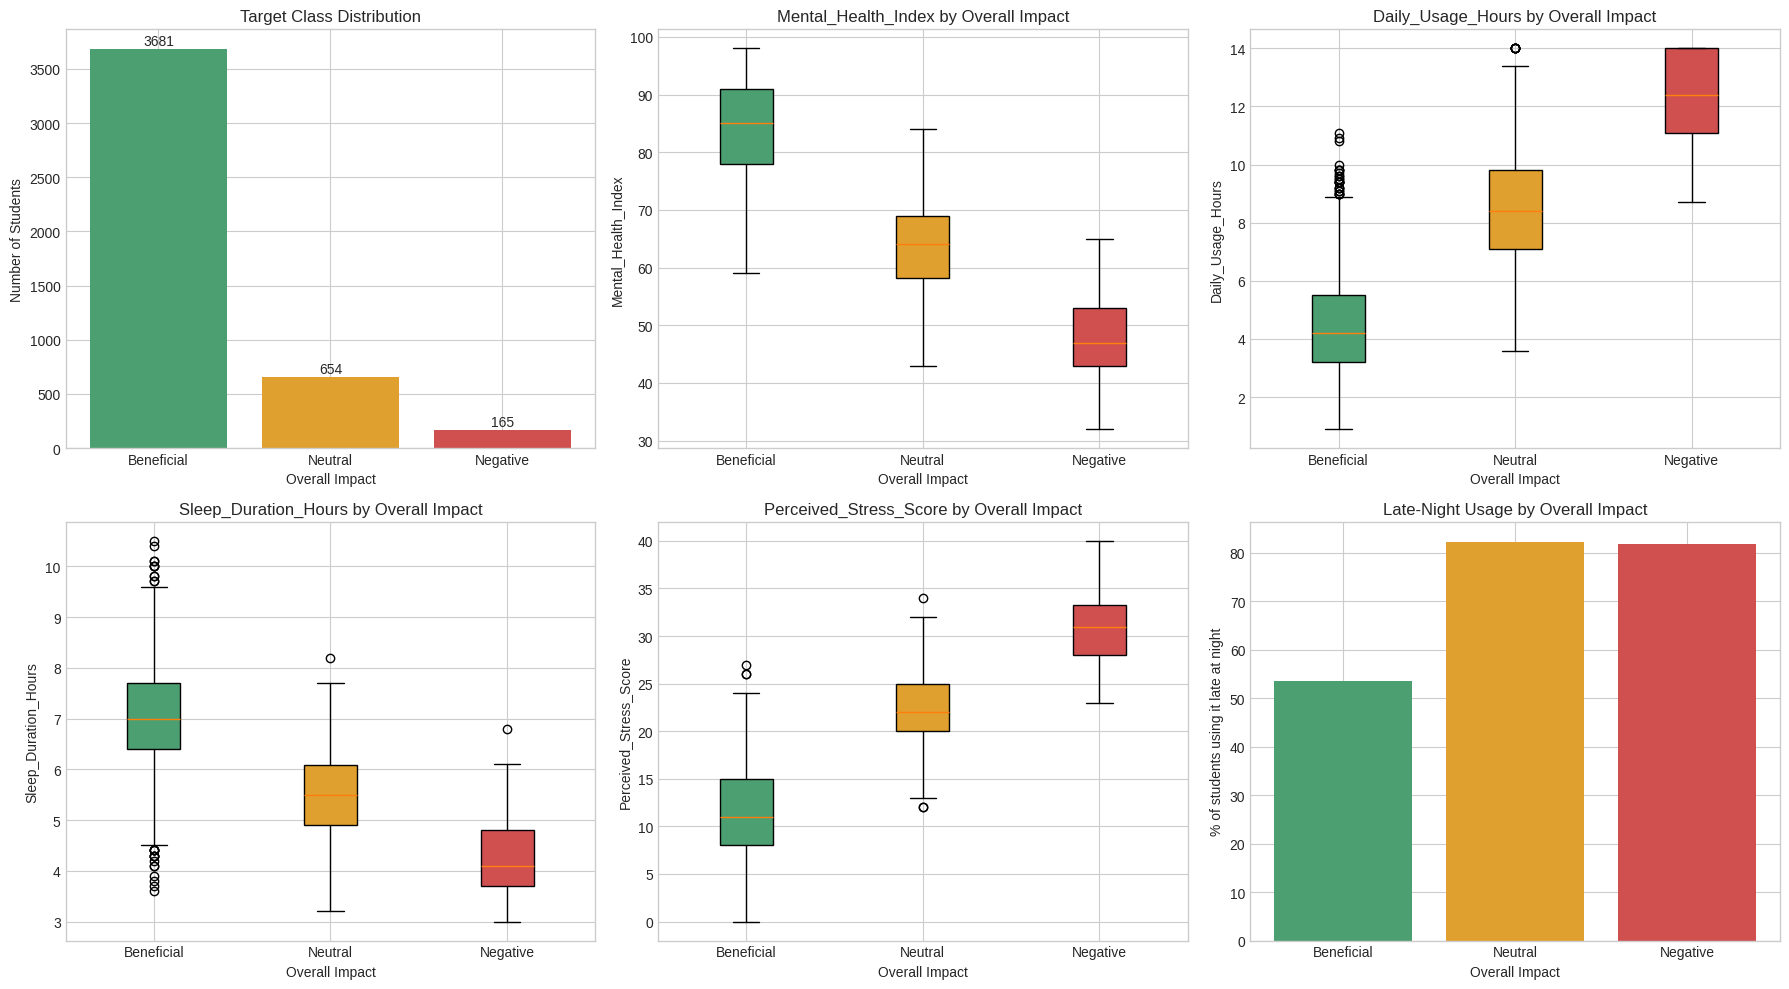

In [11]:
order = ["Beneficial", "Neutral", "Negative"]
colors = ["#4c9f70", "#e0a030", "#d05050"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Target distribution
counts = df[TARGET].value_counts().reindex(order)
axes[0, 0].bar(order, counts.values, color=colors)
axes[0, 0].set_title("Target Class Distribution")
axes[0, 0].set_xlabel("Overall Impact")
axes[0, 0].set_ylabel("Number of Students")
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v + 40, str(v), ha="center")

# 2-5. Box plots of key numeric features by class
box_features = [("Mental_Health_Index", axes[0, 1]), ("Daily_Usage_Hours", axes[0, 2]),
                ("Sleep_Duration_Hours", axes[1, 0]), ("Perceived_Stress_Score", axes[1, 1])]
for feature, ax in box_features:
    data = [df.loc[df[TARGET] == c, feature].dropna() for c in order]
    bp = ax.boxplot(data, patch_artist=True)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(order)      # set separately: the boxplot "labels" argument was renamed in newer matplotlib
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
    ax.set_title(f"{feature} by Overall Impact")
    ax.set_xlabel("Overall Impact")
    ax.set_ylabel(feature)

# 6. Share of students using social media late at night, per class
late = df.groupby(TARGET)["Late_Night_Usage"].mean().reindex(order) * 100
axes[1, 2].bar(order, late.values, color=colors)
axes[1, 2].set_title("Late-Night Usage by Overall Impact")
axes[1, 2].set_xlabel("Overall Impact")
axes[1, 2].set_ylabel("% of students using it late at night")

plt.tight_layout()
plt.show()

Average values move steadily from Beneficial to Neutral to Negative. Daily usage rises from about 4.4 hours (Beneficial) to 8.5 (Neutral) and 12.3 hours (Negative). Sleep falls from 7.0 to 5.5 to 4.2 hours, perceived stress rises from 11.2 to 22.3 to 31.1, and the Mental Health Index drops from 84.3 to 63.4 to 47.1. Late-night usage is far more common in the Neutral (82.3%) and Negative (81.8%) groups than in the Beneficial group (53.5%).

The boxes of neighbouring classes overlap (for example the Mental Health Index ranges 59–98 for Beneficial, 43–84 for Neutral and 32–65 for Negative), so no single feature separates the classes perfectly. The classes also look like an ordered scale (Beneficial, Neutral, Negative), and this shows up again in the confusion matrices later.

## **Q3. Suggest which variables are likely to be the most informative.**

Logic Used: Class-wise averages show which features differ between classes, and the correlation heatmap shows which numeric features carry the same information. Features that are highly correlated with each other matter for the model choice, because Naive Bayes assumes independent features.

Average of each numeric feature by class:


Overall_Impact,Beneficial,Neutral,Negative
Age,18.73,18.59,18.57
Daily_Usage_Hours,4.42,8.50,12.25
Weekend_Extra_Hours,1.80,1.79,1.73
Sleep_Duration_Hours,7.03,5.48,4.23
Sleep_Quality_Score,2.72,1.43,1.04
Perceived_Stress_Score,11.16,22.30,31.12
Mental_Health_Index,84.26,63.42,47.13
Academic_Performance_GPA,3.55,3.00,2.54


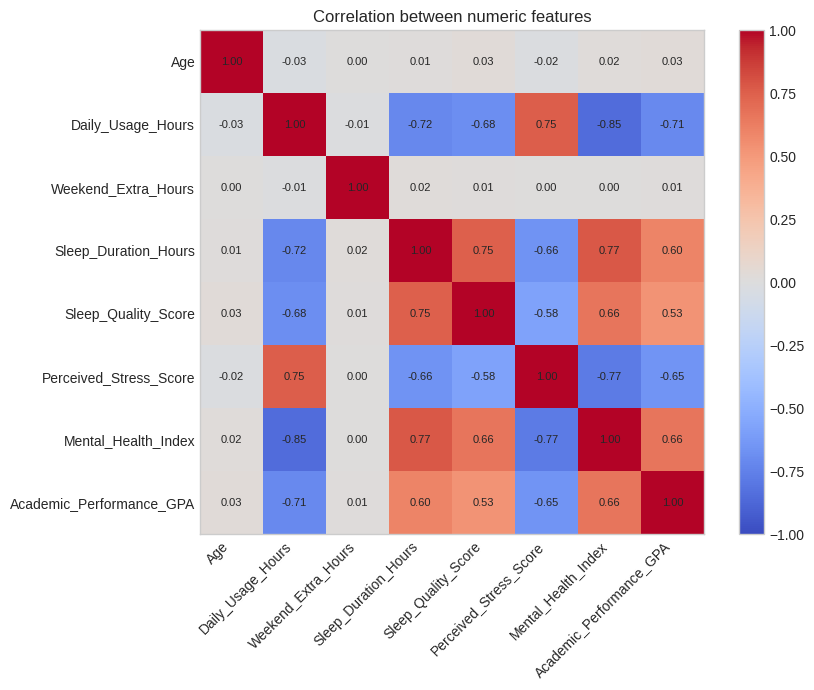

Share of each class by platform (rows add up to 1):


Overall_Impact,Beneficial,Neutral,Negative
Primary_Platform,,,
Instagram,0.821,0.143,0.036
LinkedIn,0.781,0.208,0.010
Reddit,0.821,0.135,0.044
Snapchat,0.801,0.163,0.036
TikTok,0.809,0.152,0.039
X (Twitter),0.845,0.136,0.019
YouTube,0.833,0.127,0.040


In [14]:
numeric_df = df.select_dtypes(include="number")

print("Average of each numeric feature by class:")
display(df.groupby(TARGET)[numeric_df.columns].mean().round(2).T[order])

corr = numeric_df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation between numeric features")
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

print("Share of each class by platform (rows add up to 1):")
display(pd.crosstab(df["Primary_Platform"], df[TARGET], normalize="index").round(3)[order])

Mental_Health_Index, Perceived_Stress_Score, Daily_Usage_Hours, Sleep_Duration_Hours, Sleep_Quality_Score and Academic_Performance_GPA are expected to be the most informative features: the class averages are far apart (for example GPA 3.55, 3.00 and 2.54 from Beneficial to Neutral to Negative). Age and Weekend_Extra_Hours look uninformative, as their averages are almost identical across classes and their correlation with every other feature is about 0. Primary_Platform also separates the classes weakly: the Beneficial share stays between 78% and 85% for every platform, so what matters is how much and how a student uses social media, not which app.

The informative features are strongly correlated with each other: Daily_Usage_Hours has r = -0.85 with Mental_Health_Index, +0.75 with stress, -0.72 with sleep duration and -0.71 with GPA. They carry overlapping information. This hurts Naive Bayes, which assumes independent features, and it is the first thing I will check when explaining that model's results.

## **Q4. Split the data and prepare the features.**

Logic Used: An 80/20 stratified split keeps the rare Negative class at the same proportion (3.67%) in the training and test sets. The test set is saved as `test_data.csv` with all feature columns and the target column, as the assignment requires for the Streamlit upload. All preprocessing is placed inside each model's Pipeline, so it is learned from training data only and the saved model accepts the raw CSV columns.

In [17]:
X = df.drop(columns=[TARGET, ID_COL])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTest class counts:")
print(y_test.value_counts().to_string())

# test_data.csv: all input features + the target column (uploaded in the Streamlit app)
test_df = X_test.copy()
test_df[TARGET] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("\nSaved test_data.csv with shape", test_df.shape)

Train: (3600, 14) | Test: (900, 14)

Test class counts:
Overall_Impact
Beneficial    736
Neutral       131
Negative       33

Saved test_data.csv with shape (900, 15)


In [18]:
numeric_features = ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours", "Sleep_Duration_Hours",
                    "Sleep_Quality_Score", "Perceived_Stress_Score", "Mental_Health_Index",
                    "Academic_Performance_GPA"]
categorical_features = ["Gender", "Academic_Level", "Primary_Platform", "Device_Type",
                        "Social_Comparison_Frequency"]
flag_features = ["Late_Night_Usage"]

def make_preprocessor():
    # Returns a fresh, unfitted preprocessing block. It is fitted inside every
    # model's pipeline on the training data only, so there is no data leakage.
    return ColumnTransformer(
        transformers=[
            # median imputation for the few missing values, then scaling (needed by LR, KNN, SVM)
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric_features),
            # handle_unknown="ignore" so an unseen category in an uploaded file cannot crash the app
            ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
            ("flag", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), flag_features),
        ],
        sparse_threshold=0   # always give a dense array, GaussianNB cannot use sparse input
    )

assert set(numeric_features + categorical_features + flag_features) == set(X.columns)
print("Numeric:", len(numeric_features), "| Categorical:", len(categorical_features), "| Flag:", len(flag_features))

Numeric: 8 | Categorical: 5 | Flag: 1


The split gives 3,600 training rows and 900 test rows. The test set contains 736 Beneficial, 131 Neutral and only 33 Negative students, so every Negative mistake costs about 3 percentage points of that class's recall and I keep this in mind when comparing close models. Numeric columns are median-imputed and standardised, because Logistic Regression, KNN and SVM are sensitive to feature scale. Categorical columns are one-hot encoded so that a model does not treat, for example, device types as ordered numbers. The check at the end confirms that every one of the 14 feature columns is handled by exactly one branch of the preprocessor.

## **Q5. Implement Logistic Regression, Decision Tree, KNN, Naive Bayes and SVM on the same dataset.**

Logic Used: Each model is a Pipeline (preprocessing, then classifier) tuned with 5-fold stratified GridSearchCV on the training set only. The tuning score is macro-F1 instead of accuracy, because macro-F1 gives the small Negative and Neutral classes the same weight as the large Beneficial class. `class_weight` options are searched for Logistic Regression, Decision Tree and SVM, and SVM uses `probability=True` because AUC needs predicted probabilities. The test set is not touched in this step.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 5, 10],
         "clf__criterion": ["gini", "entropy"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 7, 11, 15, 21, 31], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        # var_smoothing is wide on purpose: the one-hot columns have tiny variances
        {"clf__var_smoothing": [1e-9, 1e-6, 1e-4, 1e-2, 1e-1, 0.5, 1, 2, 5, 10]}),
    "Support Vector Machine": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1, 10, 100], "clf__kernel": ["rbf", "linear"],
         "clf__class_weight": [None, "balanced"]}),
}

best_models, tuning_rows = {}, []
for name, (estimator, grid) in search_space.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best CV macro-F1": round(search.best_score_, 4),
        "Best parameters": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
    })
    print("Finished tuning:", name)

pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(tuning_rows))

Finished tuning: Logistic Regression
Finished tuning: Decision Tree
Finished tuning: KNN
Finished tuning: Naive Bayes
Finished tuning: Support Vector Machine


,Model,Best CV macro-F1,Best parameters
0,Logistic Regression,0.9503,"{'C': 10, 'class_weight': None}"
1,Decision Tree,0.9068,"{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}"
2,KNN,0.8759,"{'n_neighbors': 11, 'weights': 'distance'}"
3,Naive Bayes,0.8865,{'var_smoothing': 0.5}
4,Support Vector Machine,0.9562,"{'C': 10, 'class_weight': None, 'kernel': 'linear'}"


All five models were trained on the same split with the same preprocessing. The selected settings are: Logistic Regression C = 10 with no class weighting, Decision Tree with the entropy criterion and no depth limit, KNN with k = 11 and distance weighting, Gaussian Naive Bayes with var_smoothing = 0.5 and SVM with a linear kernel and C = 10. The cross-validated macro-F1 values are 0.9503 (Logistic Regression), 0.9068 (Decision Tree), 0.8759 (KNN), 0.8865 (Naive Bayes) and 0.9562 (SVM).

Two details stand out. First, the "balanced" class weights were not selected for Logistic Regression or SVM, so the imbalance is handled well enough by the features themselves. Second, SVM preferred a linear kernel over RBF, which suggests the class boundary is close to linear in the standardised feature space. The chosen C values and KNN's k lie inside the searched ranges, and Naive Bayes chose a smoothing value far larger than sklearn's default of 1e-9, which acts as strong regularisation on the sparse one-hot columns.

## **Q6. Calculate Accuracy, AUC, Precision, Recall, F1 and MCC for each model.**

Logic Used: All metrics are calculated on the untouched test set using the `compute_metrics` function defined at the start. Precision, Recall and F1 are macro-averaged and AUC is one-vs-rest macro-averaged, because the target has three classes. MCC is a single score that works directly for multiple classes.

In [24]:
classes = sorted(y.unique())      # ['Beneficial', 'Negative', 'Neutral']

results = pd.DataFrame({name: compute_metrics(model, X_test, y_test)
                        for name, model in best_models.items()}).T
results.index.name = "ML Model Name"
results = results.round(4)

display(results)
print("Best model by MCC:", results["MCC"].idxmax())
print("Best model by F1 :", results["F1"].idxmax())

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9811,0.9982,0.9537,0.9466,0.9501,0.9388
Decision Tree,0.9733,0.9655,0.9158,0.9523,0.9325,0.9145
KNN,0.9456,0.9901,0.9327,0.8446,0.8841,0.8152
Naive Bayes,0.9389,0.9880,0.8780,0.9169,0.8950,0.8178
Support Vector Machine,0.9867,0.9984,0.9609,0.9648,0.9628,0.9570


Best model by MCC: Support Vector Machine
Best model by F1 : Support Vector Machine


Support Vector Machine is the best model on all six metrics (Accuracy 0.9867, AUC 0.9984, Precision 0.9609, Recall 0.9648, F1 0.9628, MCC 0.9570), followed by Logistic Regression (0.9811, 0.9982, 0.9537, 0.9466, 0.9501, 0.9388) and the Decision Tree (0.9733, 0.9655, 0.9158, 0.9523, 0.9325, 0.9145). KNN (accuracy 0.9456, MCC 0.8152) and Naive Bayes (accuracy 0.9389, MCC 0.8178) form a weaker group with very similar MCC. KNN scores higher on accuracy, AUC (0.9901 vs 0.9880) and precision (0.9327 vs 0.8780), while Naive Bayes is better on recall (0.9169 vs 0.8446) and F1 (0.8950 vs 0.8841).

The AUC values are high for every model (0.9655 to 0.9984), which means all of them rank students well. The differences are mostly in the final decisions, where macro-recall, F1 and MCC separate the models much more clearly than accuracy does.

## **Q7. Show the confusion matrices and compare the models visually.**

Logic Used: A single score hides where a model makes its mistakes. Confusion matrices show which classes get confused, the bar chart puts all six metrics of all models side by side, and the classification report of the best model gives per-class precision and recall for the rare Negative class.

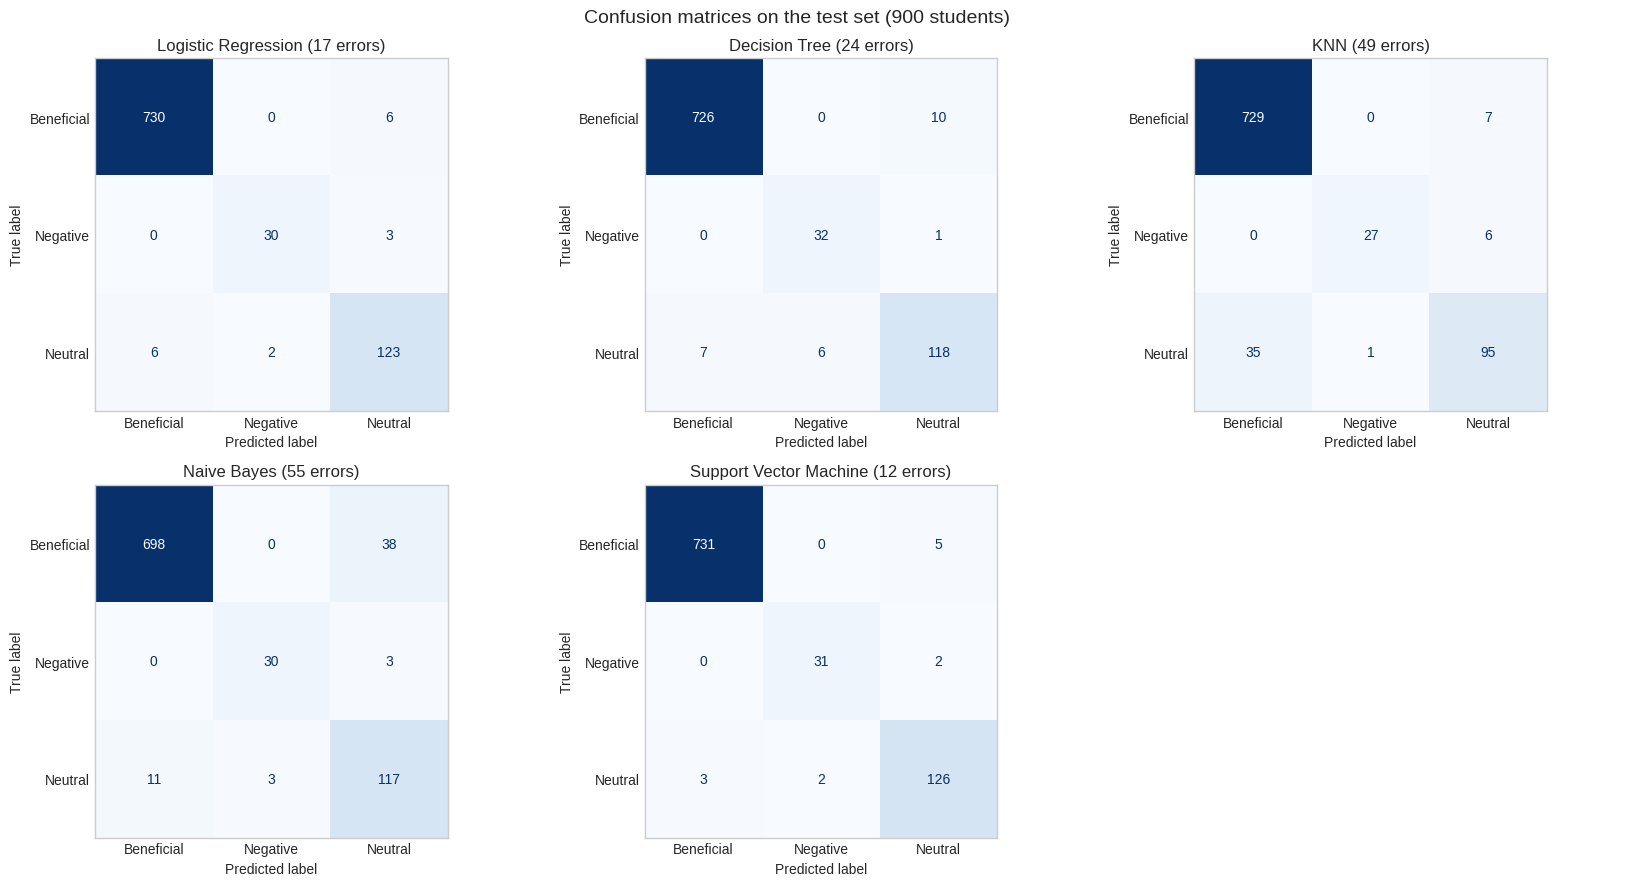

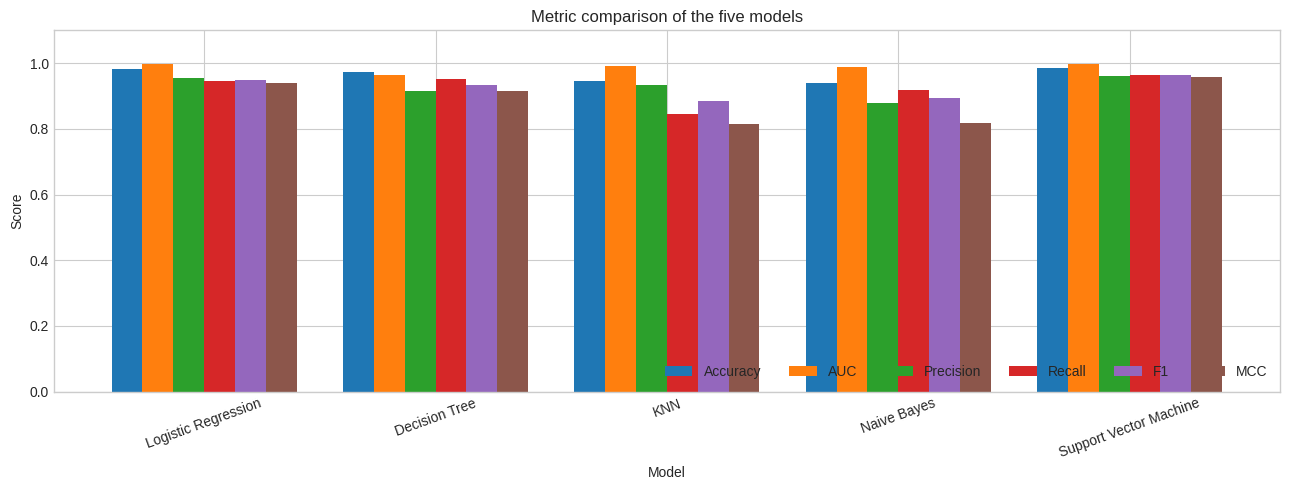

Classification report - Support Vector Machine
              precision    recall  f1-score   support

  Beneficial       1.00      0.99      0.99       736
    Negative       0.94      0.94      0.94        33
     Neutral       0.95      0.96      0.95       131

    accuracy                           0.99       900
   macro avg       0.96      0.96      0.96       900
weighted avg       0.99      0.99      0.99       900



In [27]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (name, model) in zip(axes.ravel(), best_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), labels=classes,
                                            cmap="Blues", ax=ax, colorbar=False)
    errors = int((model.predict(X_test) != y_test).sum())
    ax.set_title(f"{name} ({errors} errors)")
    ax.grid(False)
axes.ravel()[-1].axis("off")
plt.suptitle("Confusion matrices on the test set (900 students)", fontsize=14)
plt.tight_layout()
plt.show()

results.plot(kind="bar", figsize=(13, 5), width=0.8)
plt.title("Metric comparison of the five models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.legend(loc="lower right", ncol=6)
plt.tight_layout()
plt.show()

best_name = results["MCC"].idxmax()
print(f"Classification report - {best_name}")
print(classification_report(y_test, best_models[best_name].predict(X_test)))

Out of 900 test students, SVM makes 12 mistakes, Logistic Regression 17, Decision Tree 24, KNN 49 and Naive Bayes 55. Every mistake of every model is between neighbouring classes (Beneficial and Neutral, or Neutral and Negative): no model ever labels a Beneficial student as Negative or the other way round, which matches the ordered structure seen in the EDA.

The shapes of the errors differ. KNN misses many Neutral students (35 of 131 are predicted Beneficial, Neutral recall 0.73), because the nearest neighbours of a borderline student mostly belong to the large Beneficial class. Naive Bayes pushes 38 Beneficial students into Neutral, so its Neutral precision drops to 0.74. The Decision Tree finds 32 of the 33 Negative students but also labels 6 Neutral students as Negative (Negative precision 0.84). SVM is the most balanced: for the rare Negative class it gets precision 0.94 and recall 0.94 (31 of 33), and for Neutral 0.95 and 0.96.

## **Q8. Add observations on each model and decide the overall winner.**

Logic Used: The observations are based on the metric table (Q6) and the confusion matrices (Q7). Because the test set has only 33 Negative and 131 Neutral students, a difference of a few predictions is not a strong difference, and I mention this where the models are close.

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Second-best model (Accuracy 0.9811, AUC 0.9982, MCC 0.9388) with only 17 errors. The classes are close to linearly separable after scaling, so a simple linear model with C = 10 already works very well. It is also fast to train and easy to interpret. |
| Decision Tree | Good accuracy (0.9733) and high recall (0.9523), but the lowest AUC of all models (0.9655), because tree leaves give coarse probabilities. The best tree has no depth limit, which suggests some overfitting, and this shows up as lower precision (0.9158), for example 6 Neutral students wrongly flagged as Negative. |
| KNN | Accuracy 0.9456 and AUC 0.9901 look good, but its macro recall (0.8446) is the lowest: 35 of 131 Neutral students are predicted as Beneficial because the neighbours of a borderline student mostly belong to the majority class. It ranks students well, but its final labels are weaker on the minority classes. |
| Naive Bayes | The lowest accuracy (0.9389) and the lowest precision (0.8780); it labels 38 Beneficial students as Neutral. The independence assumption does not hold here, since usage, sleep, stress and mental health are strongly correlated (r up to -0.85), and one-hot columns are not Gaussian. It needed heavy smoothing (0.5) to work reasonably. |
| Support Vector Machine | Best on all six metrics (Accuracy 0.9867, AUC 0.9984, F1 0.9628, MCC 0.9570) with only 12 errors, and balanced per-class results, including 0.94 precision and recall on the rare Negative class. It also had the best cross-validated macro-F1 (0.9562). |
| **Overall, Winner for the dataset?** | **Support Vector Machine.** Logistic Regression is a very close second (it makes only 5 more mistakes out of 900), so either is a good choice, but SVM leads on every metric, including the macro-F1 and MCC that matter most for an imbalanced dataset. |

## **Q9. Explain why the winning model performs better.**

SVM performed best most likely because the three classes are separated by a boundary that is almost linear in the standardised feature space. Both SVM (linear kernel) and Logistic Regression were chosen with the highest cross-validated macro-F1 (0.9562 and 0.9503), while the more flexible or local methods were weaker. SVM's maximum-margin boundary concentrates on the students who sit close to the line between two classes, which is exactly where all the errors happen in this dataset (Beneficial/Neutral and Neutral/Negative), and this gives it a small edge over Logistic Regression. KNN is hurt by the large Beneficial class dominating the neighbourhood of borderline students, the Decision Tree overfits without a depth limit, and Naive Bayes is hurt by strongly correlated features.

## **Q10. Why is accuracy alone not enough on this dataset?**

Logic Used: A baseline that always predicts the most frequent class shows how much of the accuracy comes for free, and how MCC and macro-F1 react to it.

In [33]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Always-predict-Beneficial baseline")
print("Accuracy :", round(accuracy_score(y_test, baseline_pred), 4))
print("Macro F1 :", round(f1_score(y_test, baseline_pred, average="macro", zero_division=0), 4))
print("MCC      :", round(matthews_corrcoef(y_test, baseline_pred), 4))

Always-predict-Beneficial baseline
Accuracy : 0.8178
Macro F1 : 0.2999
MCC      : 0.0


The baseline that predicts "Beneficial" for every student reaches an accuracy of 0.8178 but an MCC of 0 and a macro-F1 of about 0.30, because it never finds a single Neutral or Negative student. This is why accuracy alone is misleading here: about 82% of the accuracy of every model is available for free. Accuracy also hides the differences between models (Logistic Regression 0.9811 against Naive Bayes 0.9389), while MCC separates them much more clearly (0.9388 against 0.8178). For this reason the comparison and the winner are based mainly on macro-F1 and MCC.

## **Saving the models and verifying them**

Logic used: Each full pipeline (preprocessing and tuned classifier) is saved as one `.joblib` file, so the Streamlit app only needs to load a file and call `predict`. To check this, the saved models are loaded again, `test_data.csv` is read back like an uploaded file and the metrics are recomputed without any retraining. If they match the results of Q6, the app will show the same numbers as this notebook.

In [36]:
file_names = {"Logistic Regression": "logistic_regression", "Decision Tree": "decision_tree",
              "KNN": "knn", "Naive Bayes": "naive_bayes", "Support Vector Machine": "svm"}

for name, model in best_models.items():
    joblib.dump(model, f"model/{file_names[name]}.joblib")

results.to_csv("model/metrics_summary.csv")
print("Files in model/:", sorted(os.listdir("model")))
print("Sizes (MB):", {f: round(os.path.getsize(f"model/{f}") / 1e6, 2) for f in sorted(os.listdir("model"))})

# Simulate the Streamlit app: load saved model + read uploaded test CSV, no retraining
uploaded = pd.read_csv("test_data.csv")
X_up, y_up = uploaded.drop(columns=[TARGET]), uploaded[TARGET]

check = pd.DataFrame({name: compute_metrics(joblib.load(f"model/{fname}.joblib"), X_up, y_up)
                      for name, fname in file_names.items()}).T.round(4)
display(check)
print("Saved models reproduce the notebook results:", check.equals(results))

Files in model/: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics_summary.csv', 'naive_bayes.joblib', 'svm.joblib']
Sizes (MB): {'decision_tree.joblib': 0.02, 'knn.joblib': 0.93, 'logistic_regression.joblib': 0.01, 'metrics_summary.csv': 0.0, 'naive_bayes.joblib': 0.01, 'svm.joblib': 0.04}


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9811,0.9982,0.9537,0.9466,0.9501,0.9388
Decision Tree,0.9733,0.9655,0.9158,0.9523,0.9325,0.9145
KNN,0.9456,0.9901,0.9327,0.8446,0.8841,0.8152
Naive Bayes,0.9389,0.9880,0.8780,0.9169,0.8950,0.8178
Support Vector Machine,0.9867,0.9984,0.9609,0.9648,0.9628,0.9570


Saved models reproduce the notebook results: True


In [52]:
import sklearn, pandas, numpy, matplotlib, joblib
for m in (sklearn, pandas, numpy, matplotlib, joblib):
    print(m.__name__, m.__version__)

sklearn 1.9.1
pandas 2.2.3
numpy 2.5.4
matplotlib 3.10.1
joblib 1.4.2
